# Assignment 2

In [1]:
import numpy as np 
import scipy as sp
import matplotlib.pyplot as plt

In [2]:
# select some fun plotting colours
colours = ['deeppink',
           'rebeccapurple',
           'crimson',
           'cornflowerblue',
           'teal',
           'forestgreen',
           'darkgoldenrod',
           'salmon'] 

## Question 1

In this problem we assume a uniform prior $P(f|I) = 1 $. 

The likelihood function is a binominal distribution with $n=90$ and $k=41$ so
$$P(D|f) = {90 \choose 41} f^{41} (1-f)^{49} $$

We need to normalize the posterior distribution by fixing $P(D)$. We find $P(D)$ by integrating the numerator of the posterior distribution: 

$$P(D) = \int_0^1 df P(D|f) P(f|I)$$


In [3]:
def q1_likelihood(f):
    '''
    Likelihood of getting 41 of 90 stars for a given fraction f. 
    '''
    return sp.special.comb(90,41)* f**41 * (1-f)**49


In [4]:
f_int = np.linspace(0,1,1000) # values of f for integration
f_plt = np.linspace(0,1,150) # values of f for plotting

In [5]:
# normalizing the distribution 
df = np.diff(f_int)[0]
marg_llh = np.sum(q1_likelihood(f_int)) * df 

Text(0.5, 1.0, 'Probability density of fraction of stars that host planetary systems.')

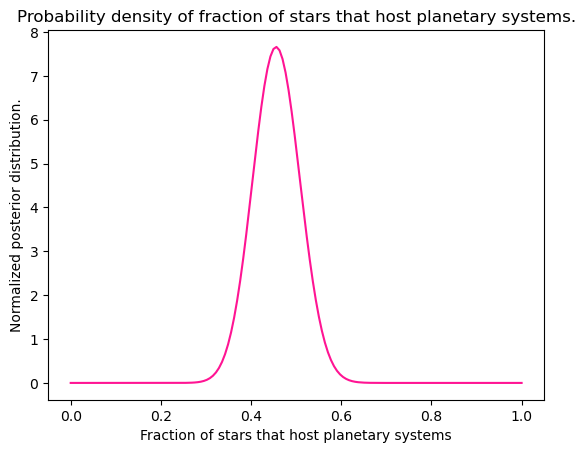

In [9]:
fig,ax = plt.subplots(1,1)

ax.plot(f_plt,q1_likelihood(f_plt)/marg_llh,color=colours[0])

ax.set_xlabel('Fraction of stars that host planetary systems')
ax.set_ylabel('Normalized posterior distribution.')

ax.set_title('Probability density of fraction of stars that host planetary systems.')

## Question 2
### Part a)

In [10]:
q2_data = np.array([5.99342831, 4.7234714, 6.29537708, 8.04605971, 4.53169325, 4.53172609, 8.15842563, 6.53486946, 4.06105123, 6.08512009])


In [11]:
def q2_loglikelihood(mu, sigma, data):
    ''' 
    '''
    N = np.shape(data)[0]
    data_shaped,mu_shaped = np.meshgrid(data, mu)
    return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization

In [12]:
mu_plt = np.linspace(0,10,100)
sigma_plt = np.linspace(0,5,100)
mu_int = np.linspace(0,10,1000)
sigma_int = np.linspace(0,5,1000)
dmu = np.diff(mu_int)[0]
dsigma = np.diff(sigma_int)[0]

mu_plt_mesh,sigma_plt_mesh = np.meshgrid(mu_plt,sigma_plt)
mu_int_mesh,sigma_int_mesh = np.meshgrid(mu_int,sigma_int)

/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: divide by zero encountered in divide
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization
/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: divide by zero encountered in log
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization
/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: invalid value encountered in subtract
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization


Text(0, 0.5, 'Value of $\\sigma$')

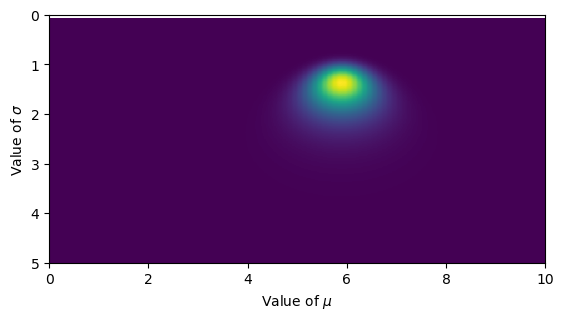

In [19]:
# NOTE: this isn't normalized but doesn't need to be to get the most likely values of mu and sigma

fig,ax = plt.subplots(1,1)
post_dist = np.exp(q2_loglikelihood(mu_plt_mesh.flatten(),sigma_plt_mesh.flatten(),q2_data).reshape(np.shape(mu_plt_mesh)))/50
plt.imshow(post_dist,
           extent=[min(mu_plt),max(mu_plt),max(sigma_plt),min(sigma_plt)])
ax.set_xlabel('Value of $\mu$')
ax.set_ylabel('Value of $\sigma$')

In [20]:
idx1,idx2 = np.where(post_dist == np.nanmax(post_dist))
idx1 = idx1.squeeze()
idx2 = idx2.squeeze()

print('The most likely values are mu =',round(mu_plt_mesh[idx1][idx2],2), 'and sigma =',str(round(sigma_plt_mesh[idx1][idx2],2))+'.')


The most likely values are mu = 5.86 and sigma = 1.36.


In [199]:
print('The mean and standard deviation from the data are mu =',round(np.mean(q2_data),2), 'and sigma =',str(round(np.std(q2_data,ddof=1),2))+'.')

The mean and standard deviation from the data are mu = 5.9 and sigma = 1.45.


### Part b)

In [21]:
post_dist_sigma = np.sum(np.exp(q2_loglikelihood(mu_int_mesh.flatten(),sigma_int_mesh.flatten(),q2_data).reshape(np.shape(mu_int_mesh)))/50,axis=1)*dmu
post_dist_mu = np.nansum(np.exp(q2_loglikelihood(mu_int_mesh.flatten(),sigma_int_mesh.flatten(),q2_data).reshape(np.shape(mu_int_mesh))).T/50,axis=1)*dsigma

/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: divide by zero encountered in divide
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization
/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: divide by zero encountered in log
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization
/var/folders/gz/v3gvmwcx05gc_d2jg_h0x28c0000gn/T/ipykernel_48688/1325988753.py:6: RuntimeWarning: invalid value encountered in subtract
  return -0.5*np.sum((data_shaped-mu_shaped)**2,axis=1)/sigma**2 - N*np.log(sigma) # omitting constant because it ends up just being normalization


The mean of mu from this distribution is 6.95 and the mean of sigma from this distribution is 2.39.
This mean and standard deviation are both higher than those found in part a).


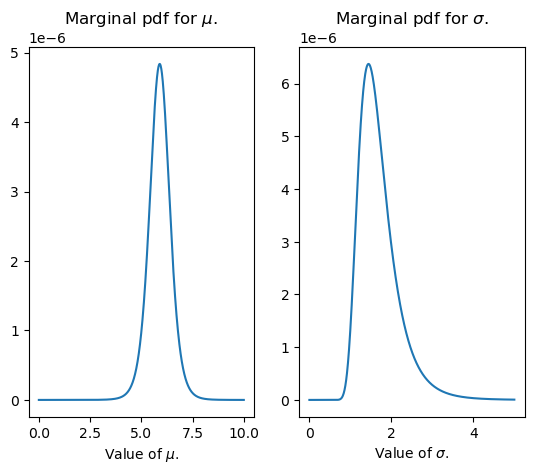

In [122]:
fig,axs = plt.subplots(1,2)

axs[0].plot(mu_int,post_dist_mu)
axs[0].set_title('Marginal pdf for $\mu$.')
axs[0].set_xlabel('Value of $\mu$.')
axs[1].plot(sigma_int,post_dist_sigma)
axs[1].set_title('Marginal pdf for $\sigma$.')
axs[1].set_xlabel('Value of $\sigma$.')

print('The mean of mu from this distribution is', round(mu_int[np.argmin(np.abs(post_dist_mu-np.mean(post_dist_mu)))],2), 'and the mean of sigma from this distribution is', str(round(sigma_int[np.nanargmin(np.abs(post_dist_sigma-np.nanmean(post_dist_sigma)))],2))+'.')
print('This mean and standard deviation are both higher than those found in part a).')

## Question 3
We can use our previous result 
$$P(a|10) = \frac{a^{10}}{10!} e^{-a}$$
as the prior. 

In [23]:
def q3_poisson(a,m):
    '''
    '''
    return a**m * np.exp(-a) / sp.special.factorial(m)

In [24]:
a_int = np.linspace(0,40,10000)
a_plt = np.linspace(0,40,1000)
da = np.diff(a_int)[0]

### Part a)

In [25]:
d_vals = np.linspace(0,40,10000)
dd = np.diff(d_vals)[0]

total = 0
for d in d_vals: # not the most optimized way to do it but that's okay
    total += np.sum(q3_poisson(a_int,d)*q3_poisson(a_int,10))*da*dd


In [ ]:
# close enough to normalized for me! 
total

0.999836156389792

In [29]:
d_vals = np.linspace(15,40,10000)
dd = np.diff(d_vals)[0]

total = 0
for d in d_vals: # not the most optimized way to do it but that's okay
    total += np.sum(q3_poisson(a_int,d)*q3_poisson(a_int,10))*da*dd

In [32]:
print('The probability of observing 15 cars or more in the second sample is', str(round(total,2))+'.')

The probability of observing 15 cars or more in the second sample is 0.19.


### Part b)

In [35]:
denom = np.sum(q3_poisson(a_int,15)*q3_poisson(a_int,10))*da
post_dist = q3_poisson(a_plt,10)*q3_poisson(a_plt,15)/denom



Text(0.5, 1.0, 'Posterior distribution of new data including prior data.')

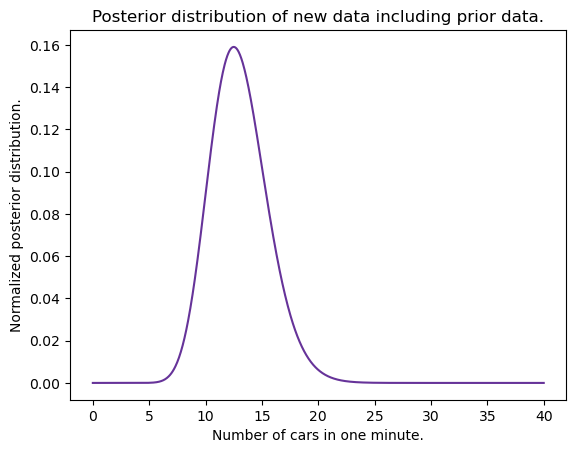

In [38]:
fig,ax = plt.subplots(1,1)
ax.plot(a_plt,post_dist,color=colours[1])
ax.set_xlabel('Number of cars in one minute.')
ax.set_ylabel('Normalized posterior distribution.')
ax.set_title('Posterior distribution of new data including prior data.')

## Question 4 
### Part a)
The difference of two independent normal distributions is a normal distribution with a mean being the difference of the two original means and the standard deviation being the sum of the two original standard deviations in quadrature.

This means that the difference in the two rates is given by 
$$N\left(180-100,\sqrt{13.4^2 + 10^2}\right) = N(80,16.7)$$

Since this is a continuous distribution we cannot give the probability that this is equal to 0, however since we know that this is centered significantly above 0, we could report the probability of the difference being less than or equal to 0 (a one-sided test.)

In [48]:
print(f'The probability that the difference is less than or equal to 0 is {sp.stats.norm.cdf(0,loc=80,scale=16.7):.2e}. \nThis is very small and does not seem consistent with the hypothesis that the data have the same Poisson rate.')

The probability that the difference is less than or equal to 0 is 8.32e-07. 
This is very small and does not seem consistent with the hypothesis that the data have the same Poisson rate.


### Part b)

In [ ]:
# sorry didn't have time to finish this 

## Question 5
See page at the end with written work.

## Question 6 
The fraction of people who actually had antibodies for COVID-19 $f$ is given by the sum of rates of true positives and false negatives:
$$f = f_{\textrm{tp}} + f_{\textrm{fn}}$$

From the data we can estimate the rate of all postive tests $f_{\textrm{p}}$, the rate of false positive tests $f_{\textrm{fp}}$, and the rate of false negative tests $f_{\textrm{fn}}$.
$$f_{\textrm{p}} \sim \textrm{Bin}(3330,50) $$
$$f_{\textrm{fp}} \sim \textrm{Bin}(3324,16) $$
$$f_{\textrm{fn}} \sim \textrm{Bin}(157,27) $$

Putting $f$ in terms of these quantities gives: 
$$f = f_{\textrm{p}} - f_{\textrm{fp}} + f_{\textrm{fn}}$$

Then, with uniform priors, the posterior distribution is given by 
$$P(f|f_{\textrm{p}},f_{\textrm{fp}},f_{\textrm{fn}}) = \frac{P(f_{\textrm{p}},f_{\textrm{fp}},f_{\textrm{fn}}|f)}{P(f_{\textrm{p}},f_{\textrm{fp}},f_{\textrm{fn}})}$$
and since $f_{\textrm{p}},f_{\textrm{fp}},f_{\textrm{fn}}$ are independent, the likelihood can be taken as the product of their likelihoods subject to the constaint for $f$ from above.

In [50]:
def q6_bin_dist(f,n,k):
    '''
    Binomial distribution
    '''
    # return sp.special.comb(n,k)* f**k * (1-f)**(n-k)
    return sp.stats.binom.pmf(k,n,f)

In [51]:
def q6_likelihood(f,ffp,ffn):
    '''
    '''
    return q6_bin_dist(f-ffp+ffn,3330,50) * q6_bin_dist(ffp,3324,16) * q6_bin_dist(ffn,157,27) 

In [ ]:
num_ints = 500

f_plt = np.linspace(0,1,num_ints)
f_int = f_plt # changed schemes later and didn't want to have to rename stuff in the code
d_f = np.diff(f_int,axis=0)


# I definitely went wrong somewhere here and got lost in the numpy of it all! 
# should've thought about it more and used scipy integrate or just approximated everything as gaussian 
# I was trying to do 3d integration without properly thinking about the shapes involved
ffp_int = np.linspace(f_int,np.ones(np.shape(f_int)),num_ints).T
d_ffp = np.diff(ffp_int,axis=1)
f_int = np.concatenate([f_int.reshape((np.shape(f_int)[0],1)) for n in range(num_ints)],axis=1)
ffn_int = np.linspace(-(f_int-ffp_int).T,np.ones(np.shape((f_int).T)),num_ints).T 
d_ffn = np.diff(ffn_int,axis=2)
ffp_int = np.concatenate([ffp_int.reshape(list(np.shape(ffp_int))+[1]) for n in range(num_ints)],axis=-1)
f_int = np.concatenate([f_int.reshape(list(np.shape(f_int))+[1]) for n in range(num_ints)],axis=-1)


d_ffp = np.append(d_ffp,d_ffp[...,-1].reshape((num_ints,1)),axis=-1)
d_ffn = np.append(d_ffn,np.take(d_ffn,-1,axis=-1).reshape((num_ints,num_ints,1)),axis=-1)

denom = np.sum(np.sum(np.sum(q6_likelihood(f_int,ffp_int,ffn_int)*d_ffn,axis=2)*d_ffp,axis=1),axis=0)*d_f[0]



/Users/josephinebrewster/anaconda3/lib/python3.10/site-packages/scipy/stats/_discrete_distns.py:77: RuntimeWarning: divide by zero encountered in _binom_pdf
  return _boost._binom_pdf(x, n, p)


/Users/josephinebrewster/anaconda3/lib/python3.10/site-packages/scipy/stats/_discrete_distns.py:77: RuntimeWarning: divide by zero encountered in _binom_pdf
  return _boost._binom_pdf(x, n, p)


Text(0.5, 1.0, 'Fraction of people with COVID-19 antibodies.')

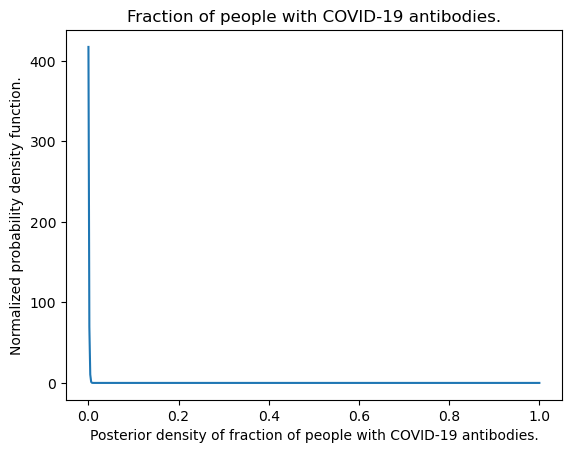

In [121]:
post_dist = np.sum(np.sum(q6_likelihood(f_int,ffp_int,ffn_int)*d_ffn,axis=2)*d_ffp,axis=1)/denom

fig,ax = plt.subplots(1,1)
ax.plot(f_plt,post_dist)

ax.set_xlabel('Posterior density of fraction of people with COVID-19 antibodies.')
ax.set_ylabel('Normalized probability density function.')
ax.set_title('Fraction of people with COVID-19 antibodies.')

Cool question! I definitely messed up my integration as this is not what the distribution should look like.